Example 34 shows the use of FS to segment a sphere for the purpose of tallying fission heating.

The segment is more complex, in this case being defined as the intersection of the outer 10cm sphere, an 8cm inner sphere, and a 20-degree cone about the y-axis and with the vertex at the origin, where the source will be located.

We can model this in OpenMC by using two separate tallies.

In [1]:
import openmc
import numpy as np
import math
import pathlib

In [2]:
# Material Definition
m1 = openmc.Material()
p = 'wo'

m1.add_element('U',1.0,p)
m1.set_density('g/cc',19.2)

materials = openmc.Materials([m1])

In [3]:
# Surface Specification
s1 = openmc.Sphere(r=10,boundary_type='vacuum')

s2 = openmc.Sphere(r=8)
#s3 = openmc.YCone(r2=(np.tan(math.pi * 20/180)**2))

# Cell specification
c1 = openmc.Cell(fill=m1,region=-s1)
c2 = openmc.Cell(fill=None,region=~c1.region)      

geometry = openmc.Geometry([c1,c2])

In the Python API, if a surface is not defined to be part of a cell, it will not be exported to xml. See that in the following, s2 which is a sphere of r=8 does not appear. 

In [4]:
geometry.export_to_xml()
%cat geometry.xml
pathlib.Path.unlink('geometry.xml')

<?xml version='1.0' encoding='UTF-8'?>
<geometry>
  <cell id="1" material="1" region="-1" universe="1"/>
  <cell id="2" material="void" region="1" universe="1"/>
  <surface id="1" type="sphere" boundary="vacuum" coeffs="0.0 0.0 0.0 10"/>
</geometry>


This particular example calls for an F7:n tally. We will create two separate tallies and manually add them at the end.

In [5]:
# Tally specification
f7_1 = openmc.Tally()
f7_sphere_mesh = openmc.SphericalMesh(r_grid=[0,8])
f7_1_filter = openmc.MeshFilter(f7_sphere_mesh)

f7_cone_mesh = openmc.SphericalMesh(r_grid=[8,10],theta_grid=[0,math.tan(10)])
f7_2_filter = openmc.MeshFilter(f7_cone_mesh)


f7_1.filters = [f7_1_filter]
f7_1.name = 'sphere'
f7_1.scores = ['heating']

f7_2 = openmc.Tally()

f7_2.filters = [f7_2_filter]
f7_2.name = 'cone'
f7_2.scores = ['heating']

tallies = openmc.Tallies(tallies=[f7_1,f7_2]) 

In [6]:
settings = openmc.Settings()
settings.run_mode='fixed source'

# Source specification
source = openmc.IndependentSource()
source.space = openmc.stats.Point((0,1,0))
source.angle = openmc.stats.Isotropic() 
source.energy = openmc.stats.delta_function(1e6) # energy in eV 
settings.source = source

# History settings
settings.particles = 200
settings.batches = 200

In [7]:
model = openmc.model.Model(geometry, materials, settings, tallies)

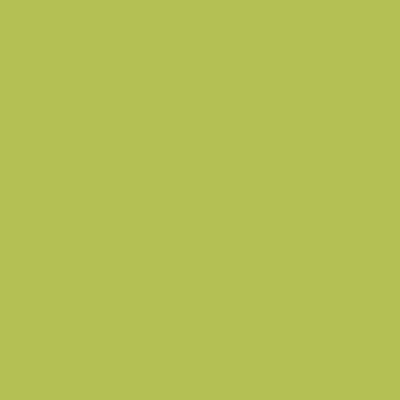

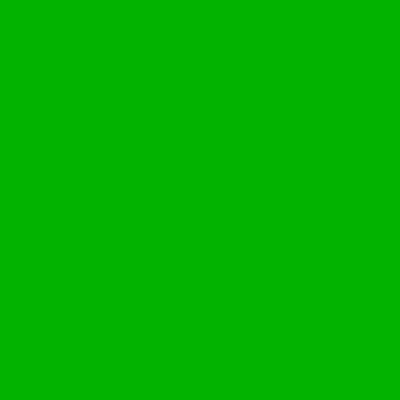

In [8]:
plots = openmc.Plots()
w = 5
origin = (0,2,0)

plot = openmc.SlicePlot()
plot.basis = 'xz'
plot.origin = origin
plot.width = (w,w)
plot.pixels = (400, 400)
plot.color_by= 'cell'
plots.append(plot)

plot = openmc.SlicePlot()
plot.basis = 'yz'
plot.origin = origin
plot.width = (w,w)
plot.pixels = (400, 400)
plot.color_by= 'material'
plots.append(plot)
openmc.plot_inline(plots)

In [9]:
sp_filename = model.run()

                                %%%%%%%%%%%%%%%
                           %%%%%%%%%%%%%%%%%%%%%%%%
                        %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                      %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                    %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                   %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                                    %%%%%%%%%%%%%%%%%%%%%%%%
                                     %%%%%%%%%%%%%%%%%%%%%%%%
                 ###############      %%%%%%%%%%%%%%%%%%%%%%%%
                ##################     %%%%%%%%%%%%%%%%%%%%%%%
                ###################     %%%%%%%%%%%%%%%%%%%%%%%
                ####################     %%%%%%%%%%%%%%%%%%%%%%
                #####################     %%%%%%%%%%%%%%%%%%%%%
                ######################     %%%%%%%%%%%%%%%%%%%%
                #######################     %%%%%%%%%%%%%%%%%%
                 #######################     %%%%%%%%%%%%%%%%%
                 #####################

In [10]:
with openmc.StatePoint(sp_filename) as sp:
    tally_res = 0
    tally_res_std = 0
    for key in (sp.tallies.keys()):
        tally_name = sp.tallies[key].name
        
        results = sp.get_tally(name=tally_name)
        df = results.get_pandas_dataframe()
        
        print(f"{tally_name} = {df['mean'].sum()} +/- {df['std. dev.'].sum()}")
        tally_res += df['mean'].sum()
        tally_res_std += df['std. dev.'].sum()

    tally_res = tally_res*(10**-6)
    tally_res_std = tally_res*(10**-6)
    print(f"total heating: {tally_res} +/- {tally_res_std} MeV per source particle")

sphere = 3072434.375065278 +/- 25252.6591882856
cone = 49003.18702420307 +/- 2310.998415309658
total heating: 3.121437562089481 +/- 3.121437562089481e-06 MeV per source particle


In [11]:
#<img src="attachment:bca17151-5ad3-4e8c-b01c-7fcb30714091.png" width="500"/> <img src="attachment:0b16a652-53c2-4985-afd7-e8d02841066b.png" width="500"/>